# Groepsgrootte 16 met vaste schaal ×64 / A32 — honderd epochs

Deze proef vergelijkt **groepsgrootte 16 met de bestaande groepsgrootte 32**, beide met vaste ×64 voor de lagere precisies. E4M3 wordt uit de actuele FP32-mastergewichten gecodeerd; E2M3 houdt de hoogste exponentbits en krijgt bronexponent +6; E2M1 ontstaat met `>>2` uit de E2M3-code en behoudt diens schaal. Activaties blijven A32.

Dit notebook leest uitsluitend opgeslagen JSON/CSV-resultaten. Het start geen training, laadt geen modelcheckpoint en berekent geen nieuwe voorspellingen. `SAVE_FIGURES=False` schrijft niets. De nieuwe honderd-epochrun start opnieuw vanuit de oorspronkelijke initialisatie; de eerdere vijfepochpilot staat apart in `pilot_reference` en wordt niet vóór deze run geplakt.


In [1]:
from pathlib import Path
RUN_DIR = Path('C:\\Users\\renzo\\master-thesis-mx\\mx_runs\\mx_triple_group16_scale64_reference100\\20261026_190508_857016_joint_run')
SAVE_FIGURES = False  # Zet op True om figuren in een nieuwe analysemap te bewaren.


In [2]:
import sys
import importlib.util
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import Markdown, display
except ImportError:
    class Markdown(str):
        pass
    def display(value):
        print(value)

# Gebruik de helper uit déze run, ook als een eerdere notebook dezelfde modulenaam gebruikte.
helper_path = RUN_DIR.expanduser().resolve() / 'notebook_support.py'
helper_name = '_mx_triple_group16_scale64_reference100_analysis_helper'
spec = importlib.util.spec_from_file_location(helper_name, helper_path)
if spec is None or spec.loader is None:
    raise FileNotFoundError(f'Analysehelper ontbreekt: {helper_path}')
ns = importlib.util.module_from_spec(spec)
sys.modules[helper_name] = ns
spec.loader.exec_module(ns)
run = ns.load_run(RUN_DIR)
figures = {}
display(Markdown(ns.status_markdown(run)))
display(ns.protocol_table(run))
display(Markdown('### Meldingen en ontbrekende gegevens'))
display(ns.diagnostics_table(run))


### Opgeslagen SVHN-run — herkomst volgens het runrapport

Runstatus: **PASS** · Analysefouten: **0**. Laatste ingelezen testepoch: **100**.

**Alle honderd epochs voor alle drie modi aanwezig; volledige referentie volgens het runrapport.** Epoch100 staat naast het door E4M3 gekozen beste checkpoint.

Deze analyse leest uitsluitend opgeslagen JSON/CSV. Zij start geen training en laadt geen model of checkpoint.

,Onderdeel,Opgeslagen configuratie
0,Gewichtsmodi,"MXFP8_E4M3, MXFP6_E2M3, MXFP4_E2M1"
1,Gewichtsroute,E4M3-bron uit actueel G(W) → E2M3 via exponent...
2,Schaal bij lagere modi,E4M3-broncode +6 in E8M0 (×64); E2M1 behoudt d...
3,Schaalgrenzen,Offset in breder integer-type; buiten eindig E...
4,STE,Identity door de volledige codebewerking naar ...
5,Schaal tijdens training,Bron wordt opnieuw bepaald uit actuele gewicht...
6,BatchNorm,Eigen doelbank per modus leert mee tijdens tra...
7,Schaalbeleid,encode current E4M3 source scale floor(log2(am...
8,Activaties / updatemaster,A32 / float32
9,Distillatie,E4M3 hard CE + E2M3 soft CE from detached E4M3...


### Meldingen en ontbrekende gegevens

,Niveau,Melding
0,RUNWAARSCHUWING,The argument 'device' of Tensor.pin_memory() i...
1,RUNWAARSCHUWING,The argument 'device' of Tensor.is_pinned() is...


## Epoch 100 en beste checkpoint gekozen door E4M3

Het beste checkpoint is het **eerste strikte maximum van de E4M3-testaccuracy**. Bij gelijke scores blijft de eerdere epoch geselecteerd. E2M3 en E2M1 worden op precies datzelfde checkpoint gerapporteerd: er is geen aparte checkpointkeuze per precisie.

Na een volledige run toont de eerste grafiek epoch 100; de tweede toont het gezamenlijke E4M3-beste checkpoint. Bij een vroege stop wordt de laatste beschikbare epoch expliciet zo genoemd en blijft epoch 100 in de tabel ongemeten.


,Rol,Controlepunt,Epoch,Gewichtsformaat,Testaccuracy [%],Correct / n,Harde test-CE,Selectiebron,Checkpoint
0,last_epoch,Laatste beschikbare epoch,100,MXFP8_E4M3,94.791026,24.676 / 26.032,0.210940,checkpoint_selection.json,last_checkpoint.pt
1,last_epoch,Laatste beschikbare epoch,100,MXFP6_E2M3,94.545175,24.612 / 26.032,0.196595,checkpoint_selection.json,last_checkpoint.pt
2,last_epoch,Laatste beschikbare epoch,100,MXFP4_E2M1,94.572065,24.619 / 26.032,0.198425,checkpoint_selection.json,last_checkpoint.pt
3,best_E4M3_test,Beste checkpoint gekozen door E4M3,53,MXFP8_E4M3,94.940842,24.715 / 26.032,0.202432,checkpoint_selection.json,best_checkpoint.pt
4,best_E4M3_test,Beste checkpoint gekozen door E4M3,53,MXFP6_E2M3,94.429932,24.582 / 26.032,0.199439,checkpoint_selection.json,best_checkpoint.pt
5,best_E4M3_test,Beste checkpoint gekozen door E4M3,53,MXFP4_E2M1,94.399201,24.574 / 26.032,0.203545,checkpoint_selection.json,best_checkpoint.pt
6,epoch100,Vast eindpunt epoch100,100,MXFP8_E4M3,94.791026,24.676 / 26.032,0.210940,alle drie modi; volledige referentie bevestigd,niet gerapporteerd
7,epoch100,Vast eindpunt epoch100,100,MXFP6_E2M3,94.545175,24.612 / 26.032,0.196595,alle drie modi; volledige referentie bevestigd,niet gerapporteerd
8,epoch100,Vast eindpunt epoch100,100,MXFP4_E2M1,94.572065,24.619 / 26.032,0.198425,alle drie modi; volledige referentie bevestigd,niet gerapporteerd


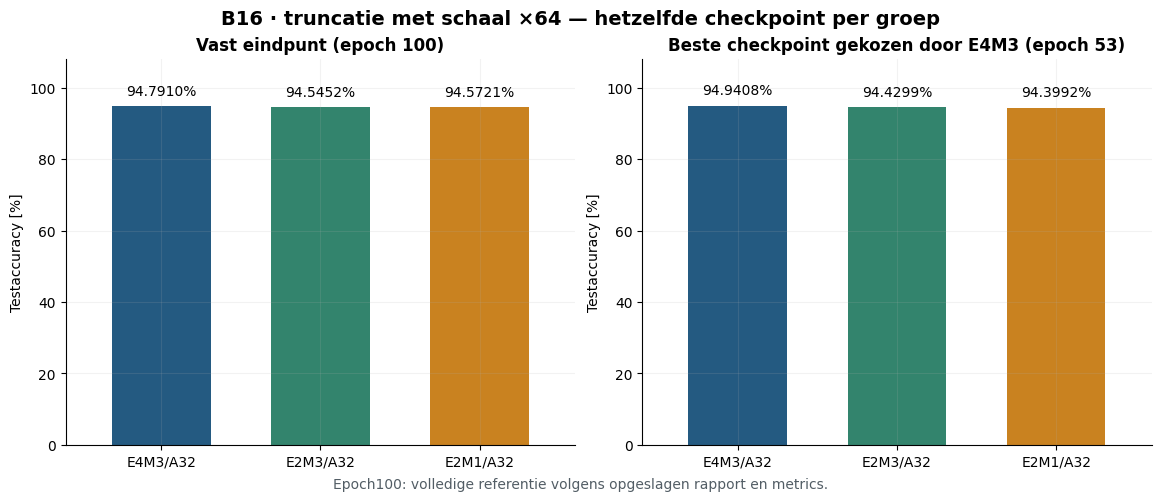

In [3]:
display(ns.checkpoint_table(run).round({'Testaccuracy [%]': 6, 'Harde test-CE': 8}))
figures['checkpoint_accuracy'] = ns.plot_checkpoint_accuracy(run)
display(figures['checkpoint_accuracy'])
plt.close(figures['checkpoint_accuracy'])


## Vergelijking met groepsgrootte 32 bij dezelfde ×64-correctie

De vastgelegde B32/×64-referentie bevat de eerdere honderd-epochtraining. De hoofdvergelijking toont **epoch 100** en het **gezamenlijke checkpoint gekozen op de hoogste E4M3-accuracy per training**. Alle drie de precisies komen steeds uit datzelfde checkpoint.

Bij een vroege stop worden curves en de keuze van het beste checkpoint voor beide runs tot dezelfde beschikbare epoch begrensd. Een B16-resultaat van epoch 100 wordt dan niet ingevuld. De oorspronkelijke initialisatie en alle relevante trainingsinstellingen moeten overeenkomen; alleen de groepsgrootte verschilt. Synthetische fixtures worden als softwaretests gemarkeerd en niet met de echte historische run vergeleken.


### Groepsgrootte 16 tegenover 32, beide met vaste ×64

De B32-cijfers komen uit de bestaande honderd-epochtraining met vaste ×64. Epoch 100 en het gezamenlijke E4M3-beste checkpoint zijn de twee belangrijkste vergelijkingspunten. Voor ieder model worden alle drie modi op één gezamenlijk checkpoint getoond; het beste checkpoint wordt uitsluitend gekozen op E4M3 binnen de gezamenlijk beschikbare epochrange. 

**Vergelijking beschikbaar voor epochs 1–100.** Dezelfde oorspronkelijke modelstaat, seed en trainingsinstellingen zijn bevestigd, afgezien van de groepsgrootte. Beide gebruiken vaste ×64. Dit garandeert geen bitexacte CUDA-herhaalbaarheid. Bij een vroege stop blijven ontbrekende epoch-100-cijfers leeg; er wordt geen accuracy voorspeld.

,Controlepunt,Gewichtsformaat,Epoch B16,Epoch B32,B16 accuracy [%],B32 accuracy [%],Verschil B16 − B32 [pp],B16 harde CE,B32 harde CE
0,Epoch 100,MXFP8_E4M3,100,100,94.791026,94.929318,-0.138291,0.210940,0.209868
1,Epoch 100,MXFP6_E2M3,100,100,94.545175,94.898586,-0.353411,0.196595,0.189969
2,Epoch 100,MXFP4_E2M1,100,100,94.572065,94.791026,-0.218961,0.198425,0.193797
3,Beste E4M3 binnen epochs 1–100,MXFP8_E4M3,53,42,94.940842,95.086816,-0.145974,0.202432,0.193877
4,Beste E4M3 binnen epochs 1–100,MXFP6_E2M3,53,42,94.429932,93.842194,0.587738,0.199439,0.221279
5,Beste E4M3 binnen epochs 1–100,MXFP4_E2M1,53,42,94.399201,93.922864,0.476337,0.203545,0.221426


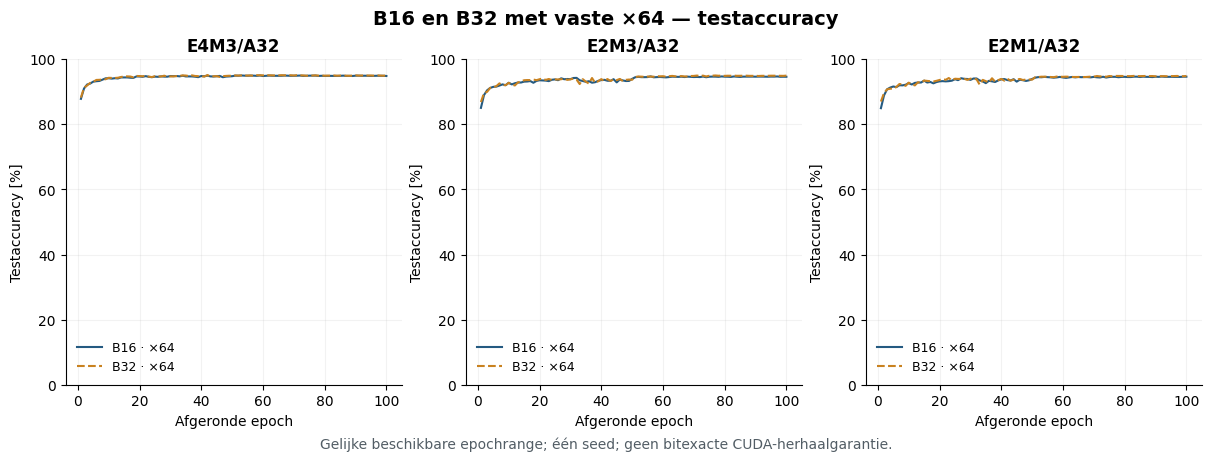

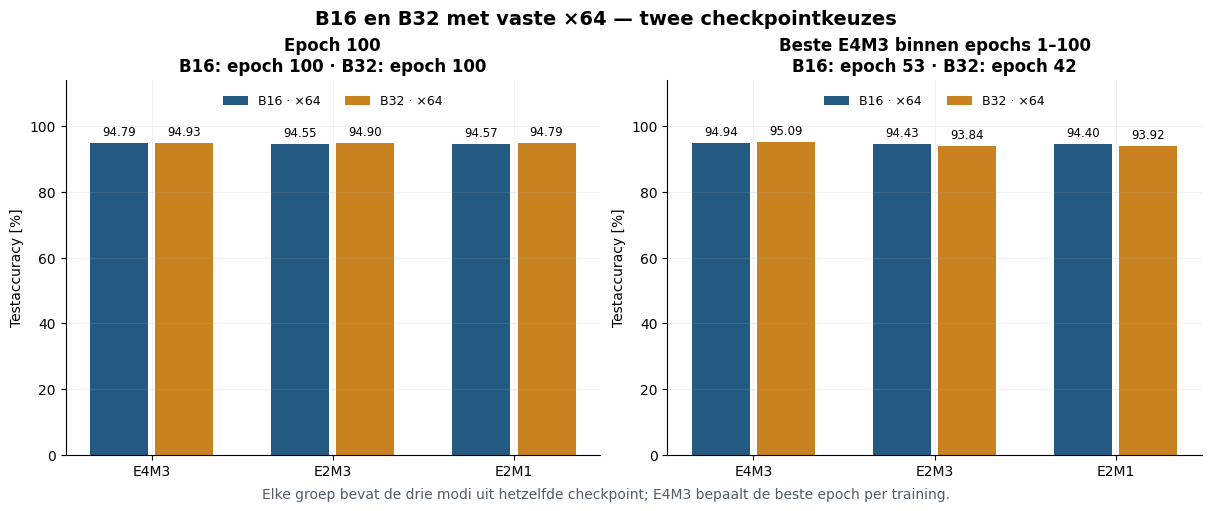

In [4]:
reference = ns.load_scale64_reference(run)
display(Markdown(ns.comparison_markdown(run, reference)))
display(ns.comparison_table(run, reference).round(6))
figures['group_comparison_curves'] = ns.plot_scale_comparison_curves(run, reference)
display(figures['group_comparison_curves'])
plt.close(figures['group_comparison_curves'])
figures['group_comparison_checkpoints'] = ns.plot_scale_comparison_checkpoints(run, reference)
display(figures['group_comparison_checkpoints'])
plt.close(figures['group_comparison_checkpoints'])


## Kosten: aantal schalen, padding en totale opslag

Elke groep heeft één E8M0-schaal van acht bits. Zonder padding kost de schaal $8/B$ bits per gewicht: 0,5 voor B16, 0,25 voor B32 en 0,125 voor B64. Onze implementatie groepeert echter per outputrij en vult elke rij tot een veelvoud van B aan.

De berekening gebeurt per laag en per precisie. Voor E4M3 tonen we ook de afzonderlijke overhead van schaalbytes en paddingcodes bovenop de reële gewichtswaarden. Dit maakt zichtbaar waarom **B64 in dit netwerk minder schalen maar toch meer bronopslag dan B32 heeft**.


Het opgeslagen geometrische kostenrapport is opnieuw berekend en bevestigd. Voor **6 van de 6** verwachte exporttabellen (drie precisies × beste/laatste checkpoint) zijn de gerapporteerde B16-groepen, padding en payload bevestigd.

De totalen betreffen uitsluitend de **129.472 reële gewichten in de zes MX-lagen**. E4M3 is de opgeslagen bron; E2M3/E2M1 zijn afzonderlijke mogelijke afgeleide exports. **Tel de drie payloadgroottes niet bij elkaar op als de opslag van één bronmodel.** Elke groep heeft één gedeelde schaal van acht bits; bij de vaste ×64-correctie wordt geen geleerde keuze per groep opgeslagen.

Zonder padding is de schaaloverhead $8/B$ bits per gewicht. Met onze groepering wordt elke outputrij apart aangevuld. Daarom gebruikt B64 ondanks minder schalen meer totale bronopslag dan B32: in de grootste laag worden 800 posities per rij bij B64 aangevuld tot 832, terwijl 16 en 32 exact passen.

**B64 in deze kostentabellen is een berekening, geen uitgevoerde accuracyproef.** FP32-uitzonderingen/BatchNorm, optimizer, bestandsmetadata en emulatorbuffers zijn uitgesloten. Deze logische bytes zijn geen checkpointbestandsgrootte, GPU-geheugenmeting, hardwarelooptijd of energiemeting.

,Groepsgrootte,Reële gewichten,Groepen / schalen,Paddingposities,Schaalbytes,Schaalbits/gewicht zonder padding,E4M3 bron + schalen [bytes],E2M3 + schalen [bytes],E2M1 + schalen [bytes],E4M3 effectieve bits/reëel gewicht,E2M3 effectieve bits/reëel gewicht,E2M1 effectieve bits/reëel gewicht
0,16,129472,8096,64,8096,0.500,137632,105248,72864,8.504202,6.503213,4.502224
1,32,129472,4080,1088,4080,0.250,134640,102000,69360,8.319328,6.302521,4.285714
2,64,129472,2160,8768,2160,0.125,140400,105840,71280,8.675235,6.539792,4.404350


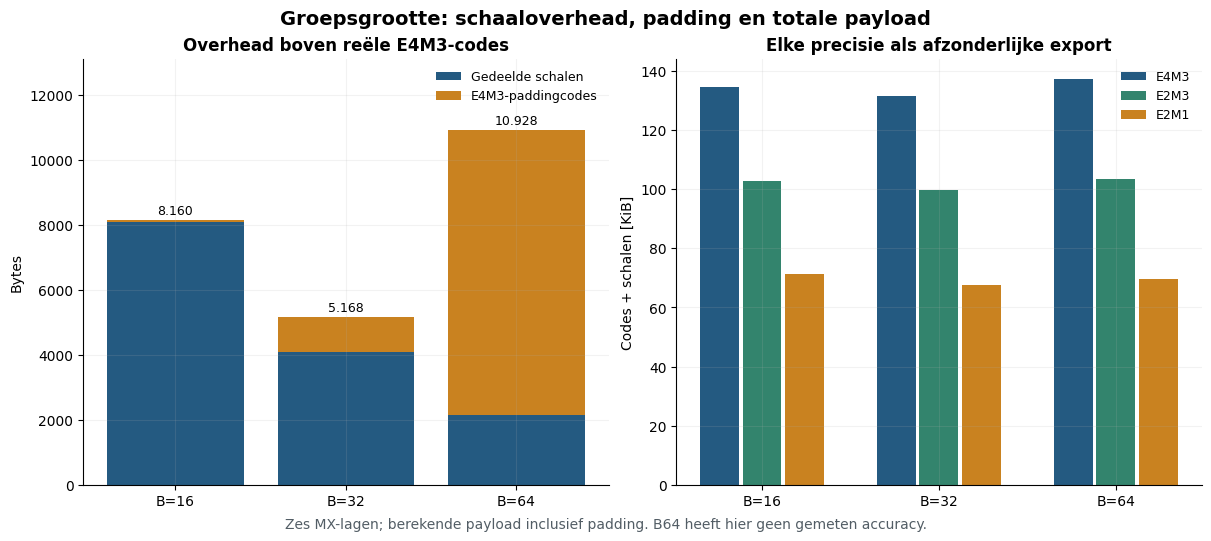

In [5]:
display(Markdown(ns.cost_markdown(run)))
display(ns.cost_summary_table(run).round(6))
figures['group_size_costs'] = ns.plot_group_costs(run)
display(figures['group_size_costs'])
plt.close(figures['group_size_costs'])


### Kosten per laag en controle tegen de opgeslagen exports

De eerste tabel geeft de berekende E4M3-bronindeling per laag bij B16/B32/B64. De lagere precisies worden met dezelfde groepsgeometrie afzonderlijk berekend. `group_size_costs_layers.csv` bevat alle lagen en alle drie de precisies.

De tweede tabel controleert B16 tegen de opgeslagen exportdiagnostiek op het beste en laatste checkpoint. Deze controle bevestigt gerapporteerde aantallen; de codec- en exporttests van de runner controleren daarnaast de werkelijke codebytes en gereconstrueerde gewichten.


In [6]:
display(ns.cost_layer_table(run, weight_bits=8))
display(ns.export_layout_table(run))


,B,Laag,Vorm,Gewichten/rij,Opgeslagen/rij,Reële gewichten,Groepen,Paddingposities,Codebytes,Schaalbytes,Code + schaal [bytes]
0,16,layers.3,"[16, 12, 3, 3]",108,112,1728,112,64,1792,112,1904
1,16,layers.6,"[16, 16, 3, 3]",144,144,2304,144,0,2304,144,2448
2,16,layers.10,"[32, 16, 3, 3]",144,144,4608,288,0,4608,288,4896
3,16,layers.13,"[32, 32, 3, 3]",288,288,9216,576,0,9216,576,9792
4,16,layers.16,"[32, 32, 3, 3]",288,288,9216,576,0,9216,576,9792
5,16,layers.20,"[128, 32, 5, 5]",800,800,102400,6400,0,102400,6400,108800
6,32,layers.3,"[16, 12, 3, 3]",108,128,1728,64,320,2048,64,2112
7,32,layers.6,"[16, 16, 3, 3]",144,160,2304,80,256,2560,80,2640
8,32,layers.10,"[32, 16, 3, 3]",144,160,4608,160,512,5120,160,5280
9,32,layers.13,"[32, 32, 3, 3]",288,288,9216,288,0,9216,288,9504


,status,reported_layout_verified,group_size,weight_bits,layers,n_weights,blocks,padded_slots,packed_weight_and_scale_bytes,role,epoch
0,PASS,True,16,8,6,129472,8096,64,137632,best,53
1,PASS,True,16,6,6,129472,8096,64,105248,best,53
2,PASS,True,16,4,6,129472,8096,64,72864,best,53
3,PASS,True,16,8,6,129472,8096,64,137632,last,100
4,PASS,True,16,6,6,129472,8096,64,105248,last,100
5,PASS,True,16,4,6,129472,8096,64,72864,last,100


## Kwantisatiefout op de twee geselecteerde checkpoints

De opgeslagen exportdiagnostiek vergelijkt de gecodeerde gewichten met de effectieve FP32-gewichten G(W), zonder een nieuwe evaluatie te starten. RMSE wordt gewogen over de reële gewichten van de zes MX-lagen; padding telt niet mee. Nieuwe nulwaarden zijn gewichten die vóór kwantisatie niet nul waren en daarna nul worden. Dit is gewichtsdiagnostiek, geen vervanging voor testaccuracy.


,checkpoint_role,checkpoint_epoch,weight_bits,layer,n_weights,mae,rmse,relative_l2,max_abs_error,new_zero_count,local_subnormal_count,out_of_element_range_before_round,scale_exponent_min,scale_exponent_max,padded_slots
0,best,53,8,layers.3,1728,0.002149,0.003016,0.028088,0.007808,0,1,0,-11,-11,64
1,best,53,8,layers.6,2304,0.002208,0.003044,0.029655,0.007798,0,0,0,-11,-11,0
2,best,53,8,layers.10,4608,0.001934,0.002788,0.028329,0.007812,0,3,0,-11,-11,0
3,best,53,8,layers.13,9216,0.001920,0.002806,0.030867,0.014297,0,0,5,-12,-11,0
4,best,53,8,layers.16,9216,0.001755,0.002738,0.032669,0.015396,0,0,16,-12,-11,0
5,best,53,8,layers.20,102400,0.000965,0.001642,0.030300,0.015625,1,6,1381,-15,-11,0
6,best,53,6,layers.3,1728,0.062111,0.084995,0.791500,0.205856,0,3,0,-5,-5,64
7,best,53,6,layers.6,2304,0.067002,0.088173,0.859084,0.205944,0,2,0,-5,-5,0
8,best,53,6,layers.10,4608,0.070986,0.090543,0.920094,0.206022,0,8,0,-5,-5,0
9,best,53,6,layers.13,9216,0.078521,0.096151,1.057591,0.206050,5,18,4,-6,-5,0


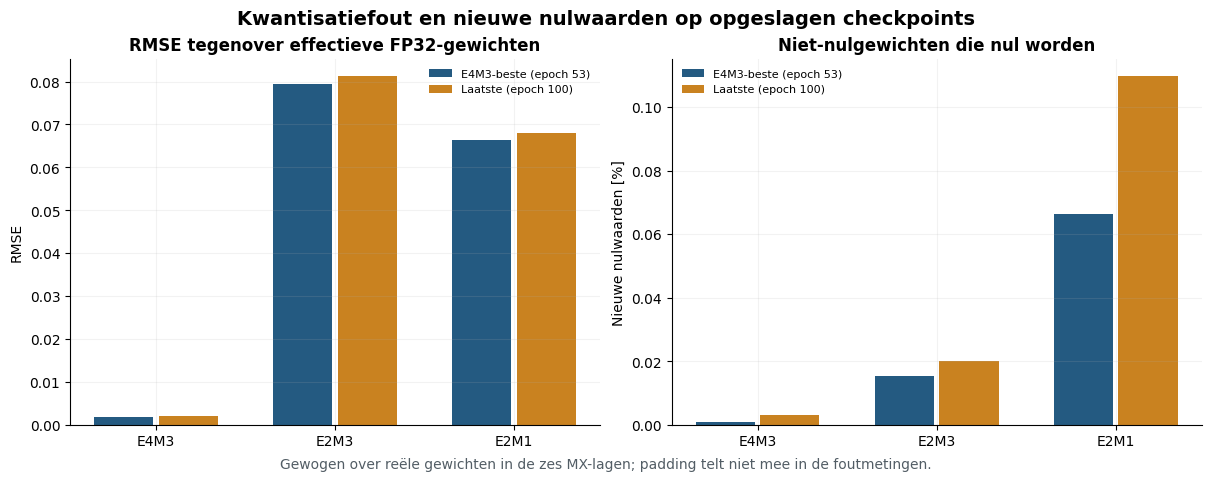

In [7]:
display(ns.quantization_table(run))
figures['quantization_diagnostics'] = ns.plot_quantization(run)
display(figures['quantization_diagnostics'])
plt.close(figures['quantization_diagnostics'])


## Train- en testaccuracy per modus

De drie modi worden gezamenlijk vanaf dezelfde oorspronkelijke initialisatie getraind. Trainaccuracy wordt tijdens de updates verzameld. Testaccuracy wordt na iedere epoch gemeten met B16 en dezelfde ×64-truncatieroute, bevroren evaluatiestaat en de volledige testset. De drie modusgebonden BatchNorm-banken leren tijdens de training normaal mee.


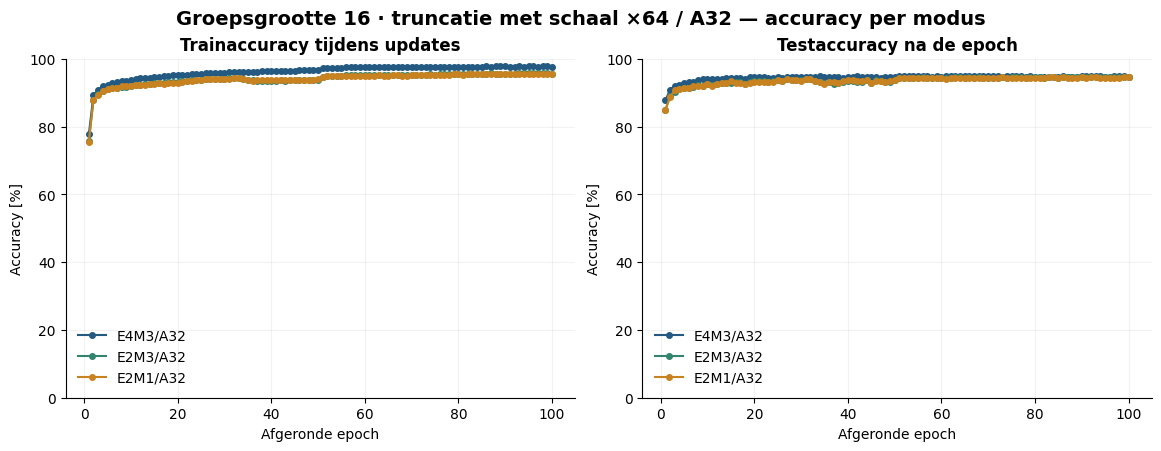

In [8]:
figures['accuracy_curves'] = ns.plot_learning(run)
display(figures['accuracy_curves'])
plt.close(figures['accuracy_curves'])


## Losses: trainingsdoelen onderscheiden van harde test-CE

De trainpass van E4M3 gebruikt harde CE van labels. Daarna leert E2M3 met soft-target CE van de **detached E4M3-softmax**; E2M1 leert met soft-target CE van de **detached E2M3-softmax**. Dit is recursieve distillatie met T=1. De drie gradients worden gesommeerd zonder deling door drie, waarna één Adam-update volgt; er is geen extra FP32-teacherforward.

De drie trainobjectieven staan in afzonderlijke panelen omdat hun targets verschillen. Soft CE is geen harde label-CE en wordt hier ook niet als KL-divergentie aangeduid. **Testloss is voor alle drie modi harde CE van dezelfde labels** en staat daarom samen in één vergelijkbaar paneel.


,epoch,phase,weight_format,objective_type,objective_loss
0,1,train,MXFP4_E2M1,recursive_soft_cross_entropy,0.919002
1,1,train,MXFP6_E2M3,recursive_soft_cross_entropy,0.882147
2,1,train,MXFP8_E4M3,hard_cross_entropy,0.693415
3,1,test,MXFP4_E2M1,hard_cross_entropy,0.483961
4,1,test,MXFP6_E2M3,hard_cross_entropy,0.480847
...,...,...,...,...,...
595,100,train,MXFP6_E2M3,recursive_soft_cross_entropy,0.176969
596,100,train,MXFP8_E4M3,hard_cross_entropy,0.076205
597,100,test,MXFP4_E2M1,hard_cross_entropy,0.198425
598,100,test,MXFP6_E2M3,hard_cross_entropy,0.196595


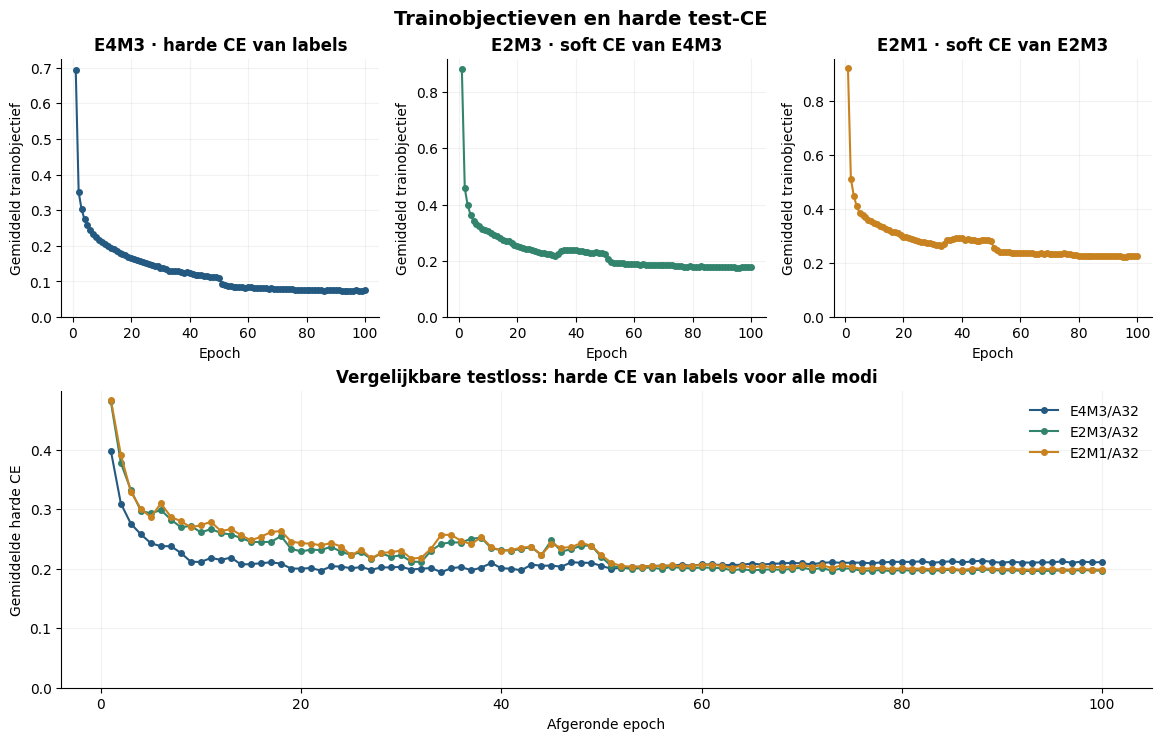

In [9]:
if not run.metrics.empty:
    objective_columns = [key for key in ('epoch', 'phase', 'weight_format', 'objective_type', 'objective_loss') if key in run.metrics]
    display(run.metrics[objective_columns].round({'objective_loss': 8}))
figures['objective_losses'] = ns.plot_objectives(run)
display(figures['objective_losses'])
plt.close(figures['objective_losses'])


## Blijft het netwerk verschillende cijfers voorspellen?

De eerdere post-hocproeven lieten bij sommige routes sterk vertekende of constante voorspellingen zien. Daarom wordt hier per testepoch en per modus bijgehouden hoe de voorspellingen over de tien cijfers verdeeld zijn. Een constante voorspelling is direct zichtbaar als **één gebruikte klasse en 100% concentratie**. De tabel toont ook hoe vaak het dominante cijfer werkelijk in de testset voorkomt.

Dit zijn geaggregeerde tellingen; deze notebook doet geen nieuwe inferentie en leidt er geen per-beeldvergelijking uit af.


,Rol,Epoch,Gewichtsformaat,Voorspelde klassen,Meest voorspelde cijfer,Aandeel dominant cijfer [%],Aandeel dat cijfer in labels [%],Testaccuracy [%],Constante voorspelling,Testbeelden,Tellingen voorspeld cijfer 0..9,Tellingen echt cijfer 0..9
0,last_epoch,100,MXFP8_E4M3,10,1,19.840965,19.587431,94.791026,False,26032,"[1775, 5165, 4148, 2852, 2501, 2353, 1982, 200...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."
1,last_epoch,100,MXFP6_E2M3,10,1,19.779502,19.587431,94.545175,False,26032,"[1795, 5149, 4139, 2843, 2510, 2344, 1975, 202...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."
2,last_epoch,100,MXFP4_E2M1,10,1,19.910111,19.587431,94.572065,False,26032,"[1785, 5183, 4145, 2846, 2508, 2344, 1954, 201...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."
3,best_E4M3_test,53,MXFP8_E4M3,10,1,19.898586,19.587431,94.940842,False,26032,"[1770, 5180, 4127, 2873, 2489, 2359, 1969, 201...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."
4,best_E4M3_test,53,MXFP6_E2M3,10,1,19.656577,19.587431,94.429932,False,26032,"[1799, 5117, 4126, 2900, 2508, 2313, 1979, 204...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."
5,best_E4M3_test,53,MXFP4_E2M1,10,1,19.779502,19.587431,94.399201,False,26032,"[1820, 5149, 4126, 2858, 2507, 2336, 1958, 204...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."


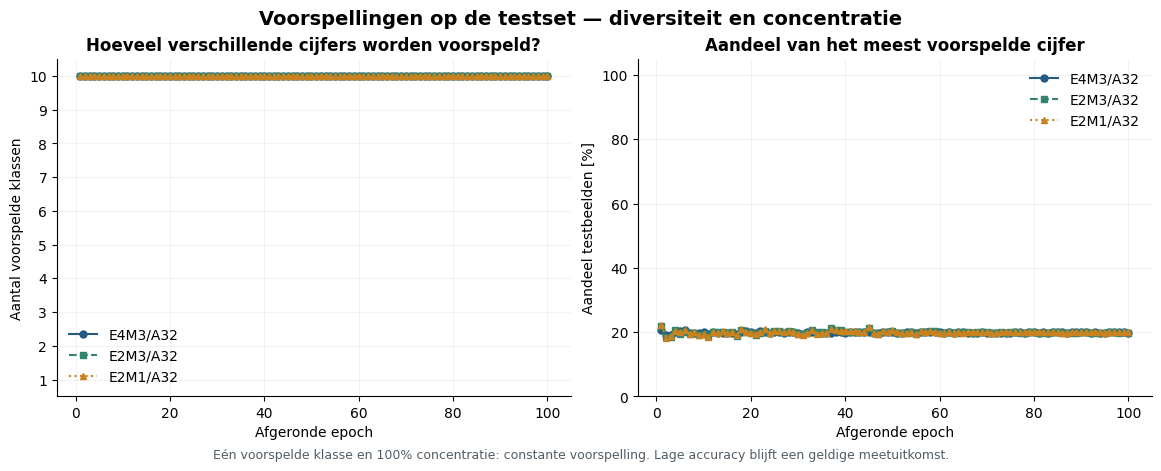

In [10]:
display(ns.prediction_table(run, selected_only=True))
figures['prediction_diversity'] = ns.plot_prediction_diversity(run)
display(figures['prediction_diversity'])
plt.close(figures['prediction_diversity'])


## Gemeten trainingsduur en eventuele projectie bij een vroege stop

**Gemeten som over 100 afgeronde epochs: 5874.07 s (97.90 minuten).** Alle honderd epochs zijn aanwezig. De gemeten duur omvat train, test, epochcontroles en checkpointschrijven; een eerdere projectie wordt hiervoor niet gebruikt. Download, installatie, data-inladen, eindrapportage en sessiepauzes zijn niet inbegrepen.

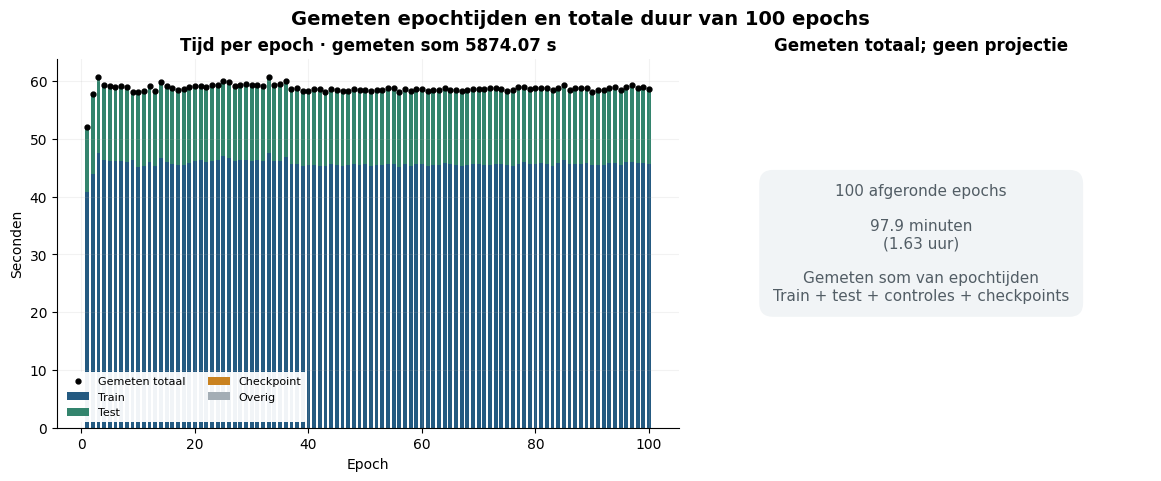

In [11]:
display(Markdown('## Gemeten trainingsduur en eventuele projectie bij een vroege stop'))
display(Markdown(ns.timing_markdown(run)))
figures['timing'] = ns.plot_timing(run)
display(figures['timing'])
plt.close(figures['timing'])


## GPU-geheugen

De opgeslagen pieken betreffen de PyTorch CUDA-allocator. Zij meten niet alle GPU-processen of compacte native MX-uitvoering. Ontbrekende waarden blijven ontbrekend.

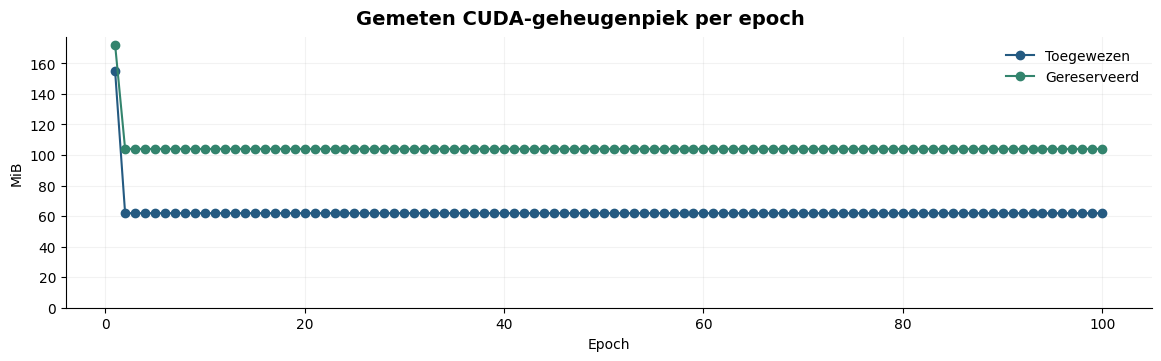

In [12]:
display(Markdown('## GPU-geheugen\n\nDe opgeslagen pieken betreffen de PyTorch CUDA-allocator. Zij meten niet alle GPU-processen of compacte native MX-uitvoering. Ontbrekende waarden blijven ontbrekend.'))
figures['gpu_memory'] = ns.plot_memory(run)
display(figures['gpu_memory'])
plt.close(figures['gpu_memory'])


In [13]:
display(Markdown('## Opgeslagen technische controles\n\nDeze tabellen rapporteren bestaande controles uit de run. Het notebook voert geen nieuwe gradient-, model- of checkpointcontrole uit.'))
display(ns.audit_table(run))
display(Markdown('### Gewichtsupdates\n\nDe mastergewichten zijn dezelfde gedeelde tensors. De herhaalde masterkolommen per modus mogen **niet bij elkaar worden opgeteld**; code- en schaalwijzigingen behoren wel bij het betreffende formaat.'))
display(ns.weight_update_table(run))
display(Markdown('### Eén opgeslagen E4M3-bron en twee afgeleide exports per geselecteerd checkpoint'))
display(ns.export_table(run))


## Opgeslagen technische controles

Deze tabellen rapporteren bestaande controles uit de run. Het notebook voert geen nieuwe gradient-, model- of checkpointcontrole uit.

,Opgeslagen controle,Resultaat volgens rapport
0,Gradientcontrole vóór iedere gezamenlijke update,True
1,FP32-masters en Adam-momenten geverifieerd,True
2,Lagere schaalcodes exact E4-bron +6,True
3,E2M1 behoudt de E2M3-schaalbytes,True
4,Eén E4-bron per laag per minibatch,True
5,Broncache leeg vóór iedere optimizerupdate,True
6,BN-tellers van alle opgeslagen epochs correct,True
7,Geen optimizerupdates tijdens evaluatie,True
8,Bronbestanden onveranderd,True
9,Ruwe datasetbestanden onveranderd,True


### Gewichtsupdates

De mastergewichten zijn dezelfde gedeelde tensors. De herhaalde masterkolommen per modus mogen **niet bij elkaar worden opgeteld**; code- en schaalwijzigingen behoren wel bij het betreffende formaat.

,epoch,weight_format,layer,master_changed_values,master_update_l2,master_dtype,changed_element_codes_including_padding,changed_scale_codes
0,1,MXFP4_E2M1,layers.3,1728,1.462086,torch.float32,1076,0
1,1,MXFP6_E2M3,layers.3,1728,1.462086,torch.float32,1545,0
2,1,MXFP8_E4M3,layers.3,1728,1.462086,torch.float32,1619,0
3,1,MXFP4_E2M1,layers.6,2304,1.714744,torch.float32,1415,1
4,1,MXFP6_E2M3,layers.6,2304,1.714744,torch.float32,2094,1
...,...,...,...,...,...,...,...,...
1795,100,MXFP6_E2M3,layers.16,9210,0.001926,torch.float32,178,0
1796,100,MXFP8_E4M3,layers.16,9210,0.001926,torch.float32,181,0
1797,100,MXFP4_E2M1,layers.20,101575,0.006834,torch.float32,266,1
1798,100,MXFP6_E2M3,layers.20,101575,0.006834,torch.float32,959,1


### Eén opgeslagen E4M3-bron en twee afgeleide exports per geselecteerd checkpoint

,Rol,Epoch,Gewichtsformaat,Bestand,Bestandsbytes,Gewichten exact gereconstrueerd,Zes FP32-masters afwezig,Volledige exporttest opnieuw,Truncatie,Bron of afleiding,E4-bronschaalbytes behouden,Schaalexponentoffset tegenover E4,Schaalfactor tegenover E4,Masters gelezen voor afleiding,Opgeslagen en herladen,Bronbestand-SHA256
0,best_E4M3_test,53,MXFP8_E4M3,mx_source_MXFP8_E4M3_best.pt,199781,True,True,False,False,E4M3-bron,True,0,1,False,True,1f2e452968de29d919cf0e1cf56f60dd7f9b019f486654...
1,best_E4M3_test,53,MXFP6_E2M3,mx_derived_MXFP6_E2M3_best.pt,168037,True,True,False,True,afgeleid uit opgeslagen E4M3-bron,False,6,64,False,True,1f2e452968de29d919cf0e1cf56f60dd7f9b019f486654...
2,best_E4M3_test,53,MXFP4_E2M1,mx_derived_MXFP4_E2M1_best.pt,135653,True,True,False,True,afgeleid uit opgeslagen E4M3-bron,False,6,64,False,True,1f2e452968de29d919cf0e1cf56f60dd7f9b019f486654...
3,last_epoch,100,MXFP8_E4M3,mx_source_MXFP8_E4M3_last.pt,199781,True,True,False,False,E4M3-bron,True,0,1,False,True,436986088e51d0ae00428418975404156ac470cd8fd17f...
4,last_epoch,100,MXFP6_E2M3,mx_derived_MXFP6_E2M3_last.pt,168037,True,True,False,True,afgeleid uit opgeslagen E4M3-bron,False,6,64,False,True,436986088e51d0ae00428418975404156ac470cd8fd17f...
5,last_epoch,100,MXFP4_E2M1,mx_derived_MXFP4_E2M1_last.pt,135653,True,True,False,True,afgeleid uit opgeslagen E4M3-bron,False,6,64,False,True,436986088e51d0ae00428418975404156ac470cd8fd17f...


## Interpretatie en grenzen

De gerichte wijziging tegenover de bestaande B32/×64-run is **groepsgrootte 16 in plaats van 32**. De schaalfactor blijft ×64; mantissatruncatie behoudt de E2M3-schaal. De andere trainingsinstellingen en de oorspronkelijke modelinitialisatie zijn gelijk.

Beoordeel de drie accuracies samen met **aantal schalen, padding en totale representatiegrootte**. Kleinere groepen kunnen een gunstiger lokale schaal geven, maar vragen meer gedeelde schalen. Onze huidige rijindeling veroorzaakt bij B64 juist meer totale bronopslag door padding. B64 in deze notebook heeft alleen een berekende kost, geen nieuw gemeten accuracy.

De software gebruikt FP32-convoluties met MX-gewichten in emulatie. GPU-geheugen en trainingstijd zijn daarom geen directe meting van een native-MX-hardwareontwerp. De run gebruikt één seed en de oorspronkelijke niet-bitexacte CUDA-backend. De officiële testset wordt ook voor checkpointselectie gebruikt; het gekozen beste resultaat is geen onafhankelijke validatie/testschatting. Ontbrekende of onvolledige gegevens blijven zichtbaar als zodanig.


In [14]:
if SAVE_FIGURES:
    analysis_dir = ns.save_figures(figures, run)
    print('Figuren opgeslagen in:', analysis_dir)
else:
    print('Alleen analyse in het notebook; geen figuren naar schijf geschreven.')
print('Ingelezen resultaatmap:', run.path)
display(pd.DataFrame({'Ingelezen bestand': [str(path.relative_to(run.path)) if path.is_relative_to(run.path) else str(path) for path in run.input_files]}))


Alleen analyse in het notebook; geen figuren naar schijf geschreven.
Ingelezen resultaatmap: C:\Users\renzo\master-thesis-mx\mx_runs\mx_triple_group16_scale64_reference100\20261026_190508_857016_joint_run


,Ingelezen bestand
0,run_report.json
1,history.json
2,training_summary.json
3,checkpoint_selection.json
4,timing_estimate.json
5,epoch_metrics.csv
6,selected_metrics.csv
7,epoch_times.csv
8,weight_updates.csv
9,group_size_costs.json
